In [2]:
import sys
!{sys.executable} -m pip install torch torchvision


In [3]:
# Imports:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os
import torch.nn as nn
import torch.optim as optim

In [4]:
import os
import kagglehub
from sklearn.model_selection import train_test_split

# 1. Download do dataset do Kaggle para o ambiente do Colab
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

# 2. Mapeamento de todos os arquivos de imagem no diretório baixado
all_files = []
for root, _, files in os.walk(path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            all_files.append(os.path.join(root, file))

# 3. Divisão aleatória em Treino (80%), Validação (10%) e Teste (10%)
train_files, temp_files = train_test_split(all_files, test_size=0.20, shuffle=True)
val_files, test_files = train_test_split(temp_files, test_size=0.50, shuffle=True)

print(f"Total de imagens encontradas: {len(all_files)}")
print(f"Conjunto de Treino (80%): {len(train_files)}")
print(f"Conjunto de Validação (10%): {len(val_files)}")
print(f"Conjunto de Teste (10%): {len(test_files)}")

Total de imagens encontradas: 24998
Conjunto de Treino (80%): 19998
Conjunto de Validação (10%): 2500
Conjunto de Teste (10%): 2500


In [5]:
# 1. Redimensionamento das imagens para 224x224
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# 2. Estrutura do Dataset para mapeamento de arquivos e rótulos
class CatDogDataset(Dataset):
    def __init__(self, file_paths, transform=None):
        self.file_paths = file_paths
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        image = Image.open(img_path).convert('RGB')

        # verifica se a pasta pai imediata é 'Dog'
        parent_dir = os.path.basename(os.path.dirname(img_path)).lower()
        label = 1.0 if parent_dir == 'dog' else 0.0

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.float32)

# 3. Instanciação dos DataLoaders com tamanho de lote igual a 500
train_dataset = CatDogDataset(train_files, transform=transform)
val_dataset = CatDogDataset(val_files, transform=transform)
test_dataset = CatDogDataset(test_files, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=50, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=50, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=50, shuffle=False)

print(f"Lotes de treino: {len(train_loader)} | Lotes de validação: {len(val_loader)} | Lotes de teste: {len(test_loader)}")

Lotes de treino: 400 | Lotes de validação: 50 | Lotes de teste: 50


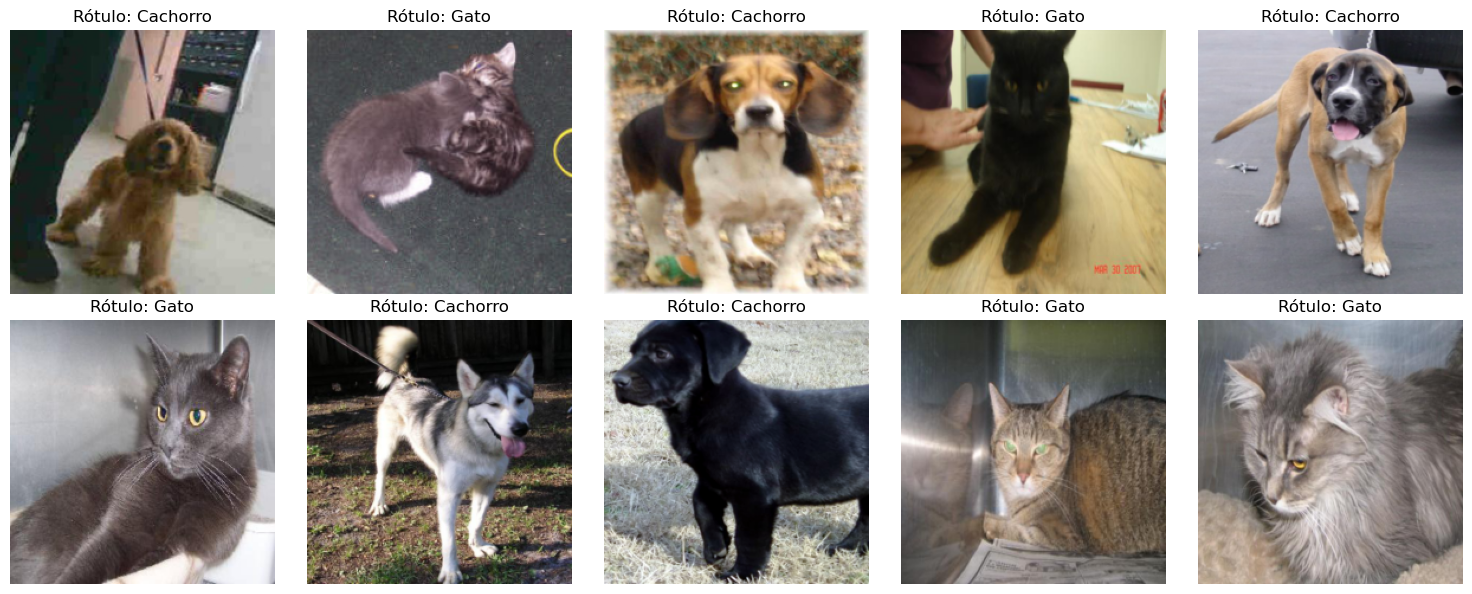

In [6]:
## so pra conferir se os rotulos tao certos:
import torch
import matplotlib.pyplot as plt
import random
import numpy as np

num_amostras = 10
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
indices_aleatorios = random.sample(range(len(train_loader.dataset)), num_amostras)

for i, idx in enumerate(indices_aleatorios):
    imagem_tensor, rotulo = train_loader.dataset[idx]
    classe_real = "Cachorro" if rotulo.item() == 1.0 else "Gato"
    # O PyTorch armazena a imagem no formato (Canais, Altura, Largura)
    # Para plotar no Matplotlib, precisamos converter para (Altura, Largura, Canais)
    imagem_numpy = imagem_tensor.permute(1, 2, 0).numpy()
    
    axes[i].imshow(imagem_numpy)
    axes[i].set_title(f"Rótulo: {classe_real}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executando no dispositivo: {device}")

class AlexNetBinary(nn.Module):
    def __init__(self):
        super(AlexNetBinary, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 384, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),

            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),

            nn.Linear(4096, 1),
            nn.Sigmoid()
        )
    # n sei se precisa mesmo disso
    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x.squeeze(-1) # garante que saída é um vetor 1D

# 2. Configurações
epochs = 5
lr = 0.0001
criterion = nn.BCELoss() # BCELoss

model = AlexNetBinary().to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)

print(f"\n==========================================")
print(f" Iniciando Treinamento Lote a Lote")
print(f"==========================================")

for epoch in range(1, epochs + 1):
    print(f"\n--- INICIANDO ÉPOCA {epoch} ---")

    # --- FASE DE TREINAMENTO ---
    model.train()
    train_loss_acumulada = 0.0
    train_correct_acumulada = 0
    train_total = 0

    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs = inputs.to(device)
        # Força o target a ser um vetor 1D idêntico à saída do modelo
        targets = targets.float().view(-1).to(device)

        optimizer.zero_grad()
        outputs = model(inputs)

        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        batch_loss = loss.item()

        predictions = (outputs >= 0.5).float()
        batch_correct = (predictions == targets).sum().item()
        batch_acc = (batch_correct / batch_size) * 100.0

        print(f"   [Treino] Época {epoch} | Lote {batch_idx+1}/{len(train_loader)} -> Perda: {batch_loss:.4f} | Acurácia: {batch_acc:.2f}%")

        # Acumula para a média final da época
        train_loss_acumulada += batch_loss * batch_size
        train_correct_acumulada += batch_correct
        train_total += batch_size

    # Calcula médias da época
    epoch_train_loss = train_loss_acumulada / train_total
    epoch_train_acc = (train_correct_acumulada / train_total) * 100.0

    # --- FASE DE VALIDAÇÃO ---
    print(f"   Avaliando conjunto de validação...")
    model.eval()
    val_loss_acumulada = 0.0
    val_correct_acumulada = 0
    val_total = 0

    with torch.no_grad():
        for batch_idx, (inputs, targets) in enumerate(val_loader):
            inputs = inputs.to(device)
            targets = targets.float().view(-1).to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            batch_size = targets.size(0)
            batch_loss = loss.item()

            predictions = (outputs >= 0.5).float()
            batch_correct = (predictions == targets).sum().item()

            # Opcional: imprimir também os lotes de validação
            # batch_acc = (batch_correct / batch_size) * 100.0
            # print(f"   [Valid] Lote {batch_idx+1}/{len(val_loader)} -> Perda: {batch_loss:.4f} | Acurácia: {batch_acc:.2f}%")

            val_loss_acumulada += batch_loss * batch_size
            val_correct_acumulada += batch_correct
            val_total += batch_size

    epoch_val_loss = val_loss_acumulada / val_total
    epoch_val_acc = (val_correct_acumulada / val_total) * 100.0

    # --- RESUMO DA ÉPOCA ---
    print(f"\n>>> RESUMO ÉPOCA {epoch} <<<")
    print(f"Treino - Perda Média: {epoch_train_loss:.4f} | Acurácia Média: {epoch_train_acc:.2f}%")
    print(f"Valid  - Perda Média: {epoch_val_loss:.4f} | Acurácia Média: {epoch_val_acc:.2f}%\n")
    print("="*50)

Executando no dispositivo: cpu

 Iniciando Treinamento Lote a Lote

--- INICIANDO ÉPOCA 1 ---
   [Treino] Época 1 | Lote 1/400 -> Perda: 0.6935 | Acurácia: 48.00%
   [Treino] Época 1 | Lote 2/400 -> Perda: 0.6926 | Acurácia: 56.00%
   [Treino] Época 1 | Lote 3/400 -> Perda: 0.6880 | Acurácia: 70.00%
   [Treino] Época 1 | Lote 4/400 -> Perda: 0.7039 | Acurácia: 42.00%
   [Treino] Época 1 | Lote 5/400 -> Perda: 0.6880 | Acurácia: 56.00%
   [Treino] Época 1 | Lote 6/400 -> Perda: 0.6994 | Acurácia: 44.00%
   [Treino] Época 1 | Lote 7/400 -> Perda: 0.6848 | Acurácia: 60.00%
   [Treino] Época 1 | Lote 8/400 -> Perda: 0.6999 | Acurácia: 44.00%
   [Treino] Época 1 | Lote 9/400 -> Perda: 0.6949 | Acurácia: 50.00%
   [Treino] Época 1 | Lote 10/400 -> Perda: 0.6931 | Acurácia: 52.00%
   [Treino] Época 1 | Lote 11/400 -> Perda: 0.6981 | Acurácia: 42.00%
   [Treino] Época 1 | Lote 12/400 -> Perda: 0.6885 | Acurácia: 58.00%
   [Treino] Época 1 | Lote 13/400 -> Perda: 0.6959 | Acurácia: 46.00%
   [T

KeyboardInterrupt: 